# Decision Tree
This notebook trains a Decision Tree to predict gallstone disease, using features from the data exploration.

### Type of machine learning:
Binary classification: 0 = gallstones, 1 = no gallstones.

### Model justification:
A Decision Tree learns simple rules from feature values. It is easy to visualize, but can overfit.


### Research question:
How well does the tree predict gallstones, and does tuning improve it?

### Splitting criteria:
The initial tree uses Gini impurity:

$$
G = 1 - (p_0^2 + p_1^2)
$$

A lower value means less mixed classes. Tuning also tests entropy.

## Training:

Data is loaded through data_loader.py, then cleaned using cells from Data_part.ipynb. HUSK Å ENDRE TIL SISTE REV HER
We keep its seven features and 80/20 stratified split (seed 37). The tree uses seed 77.
The selected features have no missing values. A tree does not need scaling.

### Initial install of libraries/packages
Uncomment if needed.

In [1]:
#%pip install -q pandas numpy scikit-learn matplotlib nbformat # installerer pakkene i notebookens Python-miljø

### Import library

In [2]:
import pandas as pd # leser CSV-filen og jobber med tabeller
import numpy as np # lager tallrekker til grafene
import matplotlib.pyplot as plt # tegner grafer
from sklearn import tree, model_selection as ms, metrics # henter trær, modellvalg og målinger

### Plot settings and class labels

In [3]:
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11}) # velger figur- og skriftstørrelse
COLORS = ["#2878A7", "#6C7A35", "#CB762D"] # velger fargene til grafene
CLASS_NAMES = ["Gallstones (0)", "No gallstones (1)"] # gir navn til klasse 0 og 1

### Reads CSV data

In [4]:
DATA_PATH = "dataset-uci.csv" # CSV-filen som ligger sammen med notebooken
data = pd.read_csv(DATA_PATH) # leser data direkte fra CSV-filen
FEATURES = [ # velger de samme sju variablene som tidligere
    "Vitamin D", # vitamin D
    "C-Reactive Protein (CRP)", # C-reaktivt protein
    "Total Body Fat Ratio (TBFR) (%)", # andel kroppsfett
    "Bone Mass (BM)", # beinmasse
    "Hemoglobin (HGB)", # hemoglobin
    "Extracellular Fluid/Total Body Water (ECF/TBW)", # forholdet mellom væske utenfor cellene og total kroppsvæske
    "Hyperlipidemia" # indikator for hyperlipidemi
]
print(f"{len(data)} patients, {len(FEATURES)} features") # viser antall pasienter og variabler

319 patients, 7 features


### Split into training and test sets

In [5]:
X = data[FEATURES] # velger variablene modellen skal bruke
y = data["Gallstone Status"] # henter fasiten: 0 = gallestein, 1 = ingen gallestein
X_train, X_test, y_train, y_test = ms.train_test_split( # deler variabler og fasit i to sett
    X, y, test_size=0.2, random_state=37, stratify=y # setter av 20 % til test med lik klassefordeling
)
cv = ms.StratifiedKFold(n_splits=5, shuffle=True, random_state=37) # lager fem faste valideringsfold
print("Training patients:", len(X_train), "Test patients:", len(X_test)) # viser størrelsen på settene

Training patients: 255 Test patients: 64


### Initial tree and max depth = 3
Compare average accuracy over five training folds. Test data is kept for evaluation.

In [6]:
decision_tree = tree.DecisionTreeClassifier(random_state=77) # lager startmodellen uten dybdegrense.
small_tree = tree.DecisionTreeClassifier(max_depth=3, random_state=77) # lager et tre med maksdybde 3.
for name, model in [("Initial tree", decision_tree), ("Depth 3 tree", small_tree)]: # tester begge trærne.
    scores = ms.cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy") # måler fem CV-resultater.
    print(f"{name}: CV accuracy = {scores.mean():.3f}") # viser gjennomsnittlig nøyaktighet for hvert tre.

Initial tree: CV accuracy = 0.714
Depth 3 tree: CV accuracy = 0.678


### Optimizing tree
GridSearchCV tests 432 combinations on training data and keeps the best average accuracy. It tests splitting rules, tree size and pruning.

In [7]:
param_grid = { # samler innstillingene søket skal prøve
    "criterion": ["gini", "entropy"], # prøver to måter å velge delinger på
    "max_depth": [2, 3, 4, 5, 6, None], # prøver ulike dybder; None betyr ingen grense
    "min_samples_split": [2, 10, 20], # minste antall pasienter for å dele en node
    "min_samples_leaf": [1, 3, 5, 10], # minste antall pasienter i en sluttnode
    "ccp_alpha": [0.0, 0.005, 0.02] # prøver ulike grader av beskjæring
}
grid_search = ms.GridSearchCV(decision_tree, param_grid, cv=cv, # setter opp søket med fem fold
                              scoring="accuracy", error_score="raise") # velger etter nøyaktighet og stopper ved feil
grid_search.fit(X_train, y_train) # tester kombinasjonene bare på treningsdata
best_tree = grid_search.best_estimator_ # henter modellen med best gjennomsnittlig CV-resultat
print("Best parameters:", grid_search.best_params_) # viser innstillingene søket valgte
print(f"Best CV accuracy: {grid_search.best_score_:.3f}") # viser modellens beste CV-gjennomsnitt

Best parameters: {'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.741


### Calculate training and testing results
All three trees use the same test set. 
- Recall measures how many gallstone cases are found
- ROC-AUC measures how well the model separates the groups.

In [8]:
models = {"Initial tree": decision_tree, "Depth 3 tree": small_tree, "Tuned tree": best_tree} # samler trærne
predictions = {} # lagring av modellens svar for testpasientene
probabilities = {} # lagring av  sannsynligheten for gallestein
rows = [] # lagring av en enkel resultatlinje per modell
for name, model in models.items(): # går gjennom alle tre modellene
    model.fit(X_train, y_train) # trener modellen på treningssettet
    predictions[name] = model.predict(X_test) # predikerer klassen til testpasientene
    probabilities[name] = model.predict_proba(X_test)[:, 0] # henter sannsynligheten for klasse 0: gallestein
    rows.append({ # legger modellens resultater i tabellen
        "Model": name, "Train accuracy": model.score(X_train, y_train), # lagrer navn og treningsnøyaktighet
        "Test accuracy": model.score(X_test, y_test), # lagrer nøyaktigheten på testsettet
        "Gallstone recall": metrics.recall_score(y_test, predictions[name], pos_label=0), # andel gallesteinstilfeller funnet
        "ROC-AUC": metrics.roc_auc_score(y_test == 0, probabilities[name]) # måler hvor godt gruppene skilles
    })
results = pd.DataFrame(rows).set_index("Model") # lager en tabell med modellnavn som radnavn
print(metrics.classification_report(y_test, predictions["Tuned tree"], # viser detaljer for det tunede treet
                                    labels=[0, 1], target_names=CLASS_NAMES, digits=3)) # bruker riktige klassenavn
results.round(3) # viser resultatene med tre desimaler

                   precision    recall  f1-score   support

   Gallstones (0)      0.786     0.688     0.733        32
No gallstones (1)      0.722     0.812     0.765        32

         accuracy                          0.750        64
        macro avg      0.754     0.750     0.749        64
     weighted avg      0.754     0.750     0.749        64



,Train accuracy,Test accuracy,Gallstone recall,ROC-AUC
Model,,,,
Initial tree,1.000,0.672,0.562,0.672
Depth 3 tree,0.769,0.797,0.719,0.891
Tuned tree,1.000,0.750,0.688,0.750


### Training and test accuracy

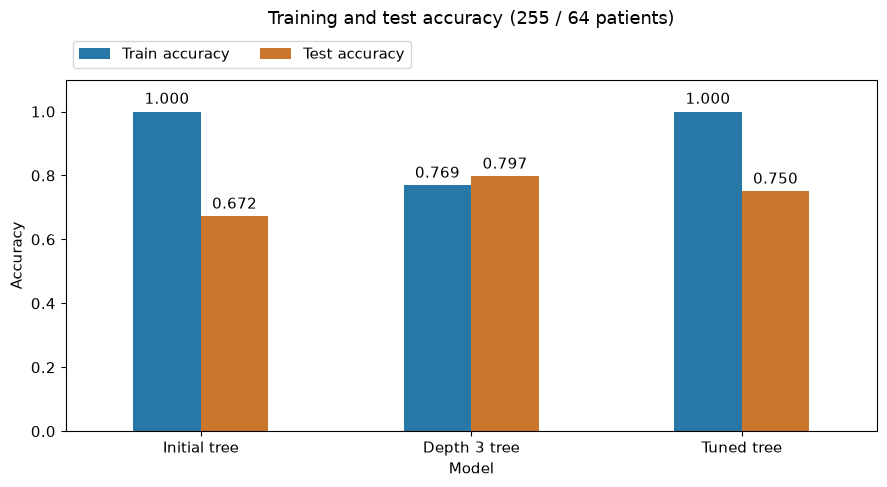

In [ ]:
ax = results[["Train accuracy", "Test accuracy"]].plot.bar( # sammenligner trenings- og testnøyaktighet
    color=[COLORS[0], COLORS[2]], rot=0, ylim=(0, 1.1) # bruker to farger, rette navn og en skala fra null
)
ax.set(xlabel="Model", ylabel="Accuracy") # gir navn til aksene
ax.set_title("Training and test accuracy (255 / 64 patients)", pad=40) # legger til tittel og plass over grafen
for bars in ax.containers: # går gjennom begge grupper med stolper
    ax.bar_label(bars, fmt="%.3f", padding=3) # skriver resultatet over hver stolpe
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=2) # plasserer fargeforklaringen over grafen
plt.tight_layout() # tilpasser avstanden slik at teksten får plass
plt.show() # viser grafen

### Confusion matrix

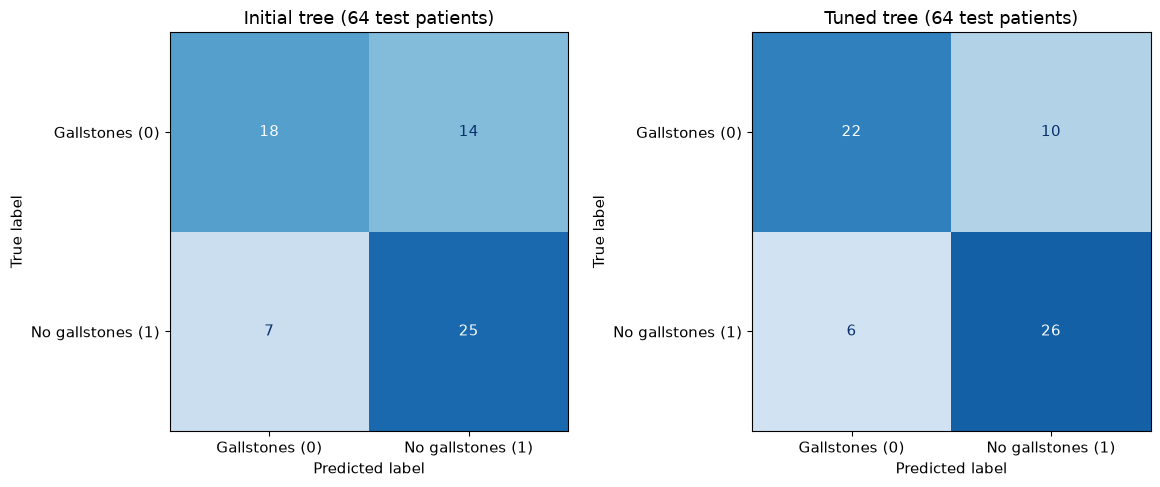

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # lager to grafer ved siden av hverandre
for ax, name in zip(axes, ["Initial tree", "Tuned tree"]): # velger ett tre til hver graf
    metrics.ConfusionMatrixDisplay.from_predictions( # sammenligner fasit med modellens svar
        y_test, predictions[name], labels=[0, 1], display_labels=CLASS_NAMES, # bruker samme klasserekkefølge
        ax=ax, cmap="Blues", colorbar=False, # tegner på riktig plass med blå farger
        im_kw={"vmin": 0, "vmax": y_test.value_counts().max()} # bruker lik fargeskala i begge grafer
    )
    ax.set_title(f"{name} (64 test patients)") # viser modellnavn og antall testpasienter
plt.tight_layout() # sørger for at navn og akser får plass
plt.show() # viser begge matrisene

### Prints results

In [12]:
testOut = pd.DataFrame({"Actual": y_test, "Predicted": predictions["Tuned tree"]}) # samler fasit og modellens svar
testOut.head(10) # viser de ti første testpasientene

,Actual,Predicted
310,1,1
130,0,0
245,1,1
144,0,1
26,0,0
239,1,1
175,1,1
126,0,1
99,0,0
247,1,1


## Conclusion (before cleansed data)
- tuning improves test accuracy from 67.2% to 75.0%
- the depth-3 tree scores 79.7% on this test set. Tuning follows training CV, not test ranking
- the tuned tree finds 22 of 32 gallstone cases, but still overfits (100% training accuracy)

### References

Decision Tree: https://scikit-learn.org/stable/modules/tree.html

Grid Search: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html